In [ ]:
!pip install tensorflow scikit-learn matplotlib
!pip install optuna
!pip install optuna-integration[tfkeras]



In [ ]:
import tensorflow as tf
import zipfile
import os

# Descomprimir los archivos zip
for zip_file in ['train.zip', 'validation.zip', 'test.zip']:
    with zipfile.ZipFile(zip_file, 'r') as zip_ref:
        zip_ref.extractall()

In [ ]:
BATCH_SIZE = 9
IMG_SIZE = (224, 224)

train_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    'train',
    validation_split=None,
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    'validation',
    validation_split=None,
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    'test',
    validation_split=None,
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)




#extraemos las clases ANTES de hacer prefetch
class_names = train_ds_raw.class_names
print("Clases detectadas:", class_names)

#Ahora optimizamos las datasets (cache, shuffle, etc.)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds_raw.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds_raw.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds_raw.cache().prefetch(buffer_size=AUTOTUNE)


Found 1034 files belonging to 3 classes.
Found 133 files belonging to 3 classes.
Found 128 files belonging to 3 classes.
Clases detectadas: ['angular_leaf_spot', 'bean_rust', 'healthy']


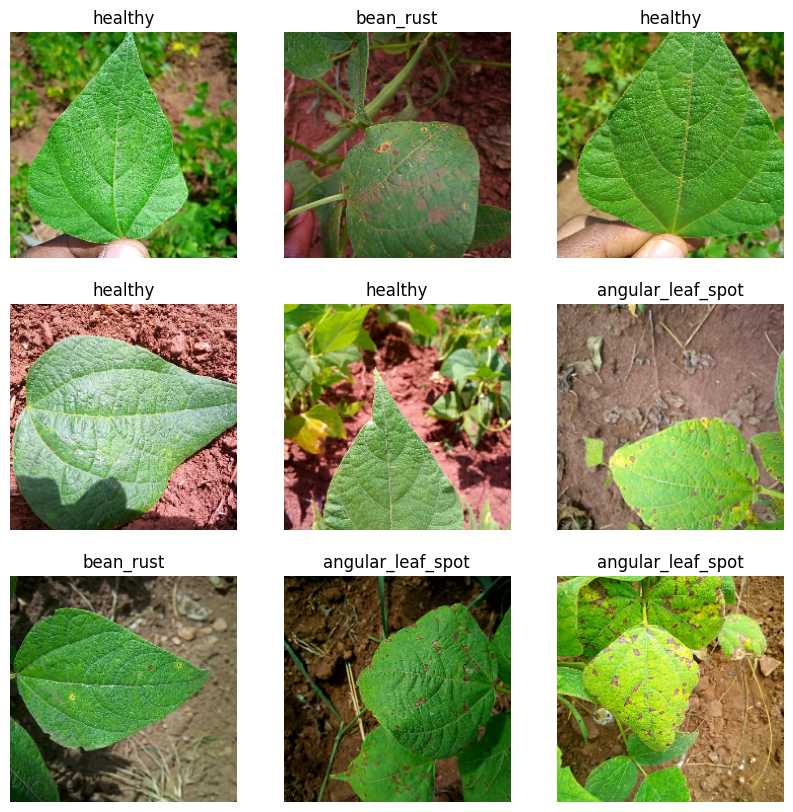

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

In [ ]:
import optuna
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from optuna.integration import TFKerasPruningCallback
from tensorflow.keras import regularizers

best_val_acc = 0

def objective(trial):
    global best_model, best_val_acc

    #regularizacion
    l2_reg = regularizers.l2(0.001)

    # Hiperparámetros a optimizar
    conv1_filters = trial.suggest_categorical('conv1_filters', [32, 64])
    conv2_filters = trial.suggest_categorical('conv2_filters', [64, 128])
    conv3_filters = trial.suggest_categorical('conv3_filters', [128, 256])
    dense_units1 = trial.suggest_categorical('dense_units', [64, 128, 256])
    learning_rate = trial.suggest_float('learning_rate', 1e-2, log=True)
    optimizer_name = trial.suggest_categorical('optimizer', ['Adam', 'sgd'])

    #Segunda preparacion pre-modelo.
    data_augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.1),
        tf.keras.layers.RandomZoom(0.1),
        ])


    # Modelo
    model = tf.keras.Sequential([
        tf.keras.layers.Rescaling(1./255, input_shape=(224, 224, 3)),
        data_augmentation,
        tf.keras.layers.Conv2D(64, (3, 3), activation='tanh', padding='same', kernel_regularizer=l2_reg),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(64, (3, 3), activation='tanh', padding='same', kernel_regularizer=l2_reg),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(128, (3, 3), activation='tanh', padding='same', kernel_regularizer=l2_reg),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(128, (3, 3), activation='tanh', padding='same', kernel_regularizer=l2_reg),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(128, (3, 3), activation='tanh', padding='same', kernel_regularizer=l2_reg),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation='tanh', kernel_regularizer=l2_reg),
        tf.keras.layers.Dense(128, activation='tanh', kernel_regularizer=l2_reg),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(3, activation='softmax')  # 3 clases: por ejemplo, rust, healthy, angular
    ])


    # Compilación
    optimizer = tf.keras.optimizers.get(optimizer_name)
    optimizer.learning_rate = learning_rate
    model.compile(optimizer=optimizer,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    callback = tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

    history = model.fit(
        train_ds_filtered,
        validation_data=val_ds_filtered,
        epochs=70,
        callbacks=[callback, TFKerasPruningCallback(trial, 'val_accuracy')]
    )

    val_loss, val_acc = model.evaluate(val_ds_filtered, verbose=0)

    # Si es el mejor modelo hasta ahora
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model = model
        model.save('best_model.keras')

        # Evaluación en test
        test_loss, test_acc = model.evaluate(test_ds_filtered)
        print(f'\nPrecisión en test: {test_acc:.4f}')

        y_true, y_pred = [], []
        for images, labels in test_ds_raw:
            preds = model.predict(images, verbose=0)
            y_true.extend(labels.numpy())
            y_pred.extend(np.argmax(preds, axis=1))

        cm = confusion_matrix(y_true, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
        disp.plot(cmap=plt.cm.Blues)
        plt.title('Matriz de Confusión')
        plt.show()

        report = classification_report(y_true, y_pred, target_names=class_names, zero_division=0)
        print(report)

        plt.figure(figsize=(8, 4))
        plt.plot(history.history['accuracy'], label='Accuracy entrenamiento')
        plt.plot(history.history['val_accuracy'], label='Accuracy validación')
        plt.legend()
        plt.title('Accuracy durante entrenamiento')
        plt.show()

        plt.figure(figsize=(8, 4))
        plt.plot(history.history['loss'], label='Loss entrenamiento')
        plt.plot(history.history['val_loss'], label='Loss validación')
        plt.legend()
        plt.title('Loss durante entrenamiento')
        plt.show()

    return val_acc

# Estudio de Optuna
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)

print("==========================================================")
print("Mejores hiperparámetros:", study.best_params)
print("Mejor precisión en validación:", study.best_value)
print("==========================================================")

[I 2025-05-18 21:45:18,222] A new study created in memory with name: no-name-bf831c15-a47b-4536-89b2-e6c31695cb4c


Epoch 1/70


/usr/local/lib/python3.11/dist-packages/keras/src/layers/preprocessing/tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


115/115 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - accuracy: 0.3071 - loss: 2.1696 - val_accuracy: 0.3459 - val_loss: 2.1695
Epoch 2/70
115/115 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.2829 - loss: 2.1696 - val_accuracy: 0.3308 - val_loss: 2.1695
Epoch 3/70
115/115 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.3449 - loss: 2.1695 - val_accuracy: 0.3534 - val_loss: 2.1695
Epoch 4/70
115/115 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.3543 - loss: 2.1695 - val_accuracy: 0.3759 - val_loss: 2.1695
Epoch 5/70
115/115 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.3624 - loss: 2.1695 - val_accuracy: 0.3534 - val_loss: 2.1694
Epoch 6/70
115/115 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.3565 - loss: 2.1694 - val_accuracy: 0.3459 - val_loss: 2.1694
Epoch 7/70
115/115 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.3464 - loss: 2.1694 - val_accuracy: 0.3459 - val_loss: 2.1694
Epoch 8/70
115/115 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.3527 - loss: 2.1694 - val_accuracy: 0.338

[W 2025-05-18 21:45:48,465] Trial 0 failed with parameters: {'conv1_filters': 32, 'conv2_filters': 64, 'conv3_filters': 128, 'dense_units': 128, 'learning_rate': 2.3705997643237814e-05, 'optimizer': 'sgd'} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/optuna/study/_optimize.py", line 197, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "<ipython-input-37-2d25ea6e78aa>", line 64, in objective
    history = model.fit(
              ^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/keras/src/utils/traceback_utils.py", line 117, in error_handler
    return fn(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/keras/src/backend/tensorflow/trainer.py", line 371, in fit
    logs = self.train_function(iterator)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/keras/src/bac

KeyboardInterrupt: 

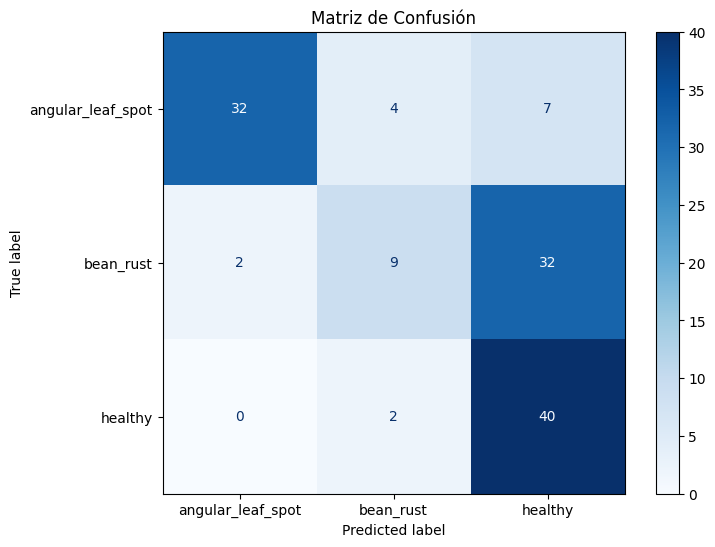

                   precision    recall  f1-score   support

angular_leaf_spot       0.94      0.74      0.83        43
        bean_rust       0.60      0.21      0.31        43
          healthy       0.51      0.95      0.66        42

         accuracy                           0.63       128
        macro avg       0.68      0.64      0.60       128
     weighted avg       0.68      0.63      0.60       128



In [ ]:
from tensorflow.keras.models import load_model
import os
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Cargar modelo guardado
model = load_model('best_model.keras')

# Predecir sobre test_ds_raw
y_true, y_pred = [], []
for images, labels in test_ds_raw:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

# Matriz de confusión
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

# Crear carpeta para guardar resultados
os.makedirs("reporte_best_model", exist_ok=True)


# Mostrar y guardar matriz de confusión
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title('Matriz de Confusión')
plt.savefig("reporte_best_model/matriz_confusion.png")
plt.show()  # Esto muestra la figura en pantalla

# Reporte de clasificación
report = classification_report(y_true, y_pred, target_names=class_names)
print(report)


Saving bean_rust_val.32.jpg to bean_rust_val.32.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 426ms/step


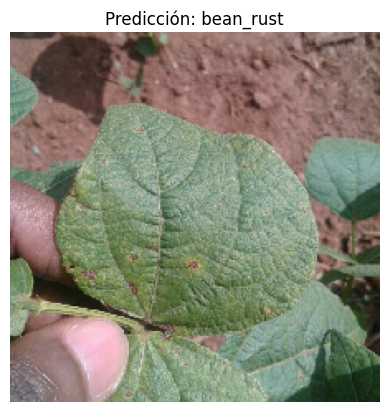

✅ La imagen 'bean_rust_val.32.jpg' fue clasificada como: bean_rust


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from google.colab import files
from tensorflow.keras.models import load_model
import numpy as np
import matplotlib.pyplot as plt

# Cargar el modelo guardado
model = load_model('best_model.keras')

# Subir imagen
uploaded = files.upload()

for img_name in uploaded.keys():
    # Cargar y preparar la imagen
    img = image.load_img(img_name, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0) / 255.0  # Normalizar como en el entrenamiento

    # Hacer prediccióna
    predictions = model.predict(img_array)
    predicted_class = class_names[np.argmax(predictions)]

    # Mostrar resultado
    plt.imshow(img)
    plt.title(f"Predicción: {predicted_class}")
    plt.axis('off')
    plt.show()

    print(f"✅ La imagen '{img_name}' fue clasificada como: {predicted_class}")
